# Wspólna analiza cen paliw i żywności w Polsce (2019-2025)
Wpływ zmian cen paliw na wartość koszyka podstawowych potrzeb konsumenta.


---


# **Główne pytanie badawcze**
Czy i w jakim stopniu zmiany oraz zmienność cen paliw były powiązane ze zmianami cen podstawowych produktów spożywczych i możliwościami zakupowymi za stałą kwotę w Polsce w latach 2019-2025?

Pytania szczegółowe:
1. Czy wzrostom cen paliw towarzyszyły wzrosty cen żywności?
2. Czy ceny paliw i żywności zmieniały się w podobnym tempie?
3. Czy zmiany cen paliw były związane ze zmianami kosztu koszyka żywnościowego?
4. Czy wzrost kosztu koszyka ograniczył możliwości zakupowe konsumentów?
5. Czy w latach większej zmienności cen paliw obserwowano większe podwyżki cen żywności?

Hipotezy:
- H1: Wzrostom cen paliw towarzyszą wzrosty cen podstawowych produktów spożywczych,
- H2: Wzrost kosztu produktów podstawowej potrzeby zmniejsza liczbę koszyków możliwych do zakupu za stałą kwotę,
- H3: Większa zmienność cen paliw wiąże się z większymi wzrostami kosztu koszyka żywnościowego./

In [1]:
#import bibliotek
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
if not Path("jedzenie_clean.csv").exists() or not Path("paliwa_jak_jedzenie.csv").exists():
    from google.colab import files
    files.upload()

jedzenie = pd.read_csv("jedzenie_clean.csv", sep=";", decimal=",")
paliwa_jak_jedzenie = pd.read_csv("paliwa_jak_jedzenie.csv", sep=";", decimal=",")

display(jedzenie.head())
display(paliwa_jak_jedzenie.head())

,Produkt,2019,2020,2021,2022,2023,2024,2025,zmiana_2019_2025
0,ryż - za 1kg,3.96,4.24,4.59,5.72,6.48,6.23,6.32,59.595960
1,"chleb pszenno-żytni - za 0,5kg",2.66,2.91,3.17,4.16,4.82,5.13,5.38,102.255639
2,makaron jajeczny - za 400g,4.26,4.48,4.67,5.49,6.42,6.60,6.49,52.347418
3,mąka pszenna - za 1kg,2.73,2.97,3.10,4.20,4.08,3.87,3.76,37.728938
4,mięso wieprzowe bez kości (schab) - za 1 kg,18.99,19.17,17.99,21.84,25.73,26.02,25.04,31.858873


,Produkt,2019,2020,2021,2022,2023,2024,2025
0,ONEkodiesel,4.02625,3.34900,4.22825,6.69225,5.1270,4.98450,4.6635
1,Pb95,3.91150,3.43075,4.36150,5.94125,5.1215,4.90200,4.5070
2,Pb98,4.11575,3.59800,4.60000,6.38575,5.4935,5.42175,4.9495


In [3]:
#lata analizy
lata = [str(rok) for rok in range(2019, 2026)]

#walidacja cen
jedzenie[lata] = jedzenie[lata].apply(pd.to_numeric, errors="coerce")
paliwa_jak_jedzenie[lata] = paliwa_jak_jedzenie[lata].apply(pd.to_numeric, errors="coerce")

#obrocenie tabeli: wiersze to lata, kolumny to paliwa
paliwa_roczne = paliwa_jak_jedzenie.set_index("Produkt")[lata].T
paliwa_roczne.index = paliwa_roczne.index.astype(int)
paliwa_roczne.index.name = "rok"
paliwa_roczne = paliwa_roczne[["ONEkodiesel", "Pb95", "Pb98"]]

print("Braki w cenach zywnosci:", jedzenie[lata].isna().sum().sum())
print("Braki w cenach paliw:", paliwa_roczne.isna().sum().sum())
print("Liczba produktow:", len(jedzenie))
display(paliwa_roczne.round(3))

Braki w cenach zywnosci: 0
Braki w cenach paliw: 0
Liczba produktow: 13


Produkt,ONEkodiesel,Pb95,Pb98
rok,,,
2019,4.026,3.912,4.116
2020,3.349,3.431,3.598
2021,4.228,4.362,4.600
2022,6.692,5.941,6.386
2023,5.127,5.121,5.494
2024,4.985,4.902,5.422
2025,4.664,4.507,4.950


Przygotowanie koszyka analitycznego i połączenie danych

In [4]:
#suma cen 13 produktow w kazdym roku
koszyk_roczny = jedzenie[lata].sum(axis=0, min_count=len(jedzenie))
koszyk_roczny.index = koszyk_roczny.index.astype(int)
koszyk_roczny.name = "Koszyk_13_prod"

#tabela kosztu koszyka
koszt_koszyka = koszyk_roczny.to_frame()
koszt_koszyka["Zmiana_rdr_%"] = koszyk_roczny.pct_change(fill_method=None) * 100

display(koszt_koszyka.round(2))
print("Zmiana kosztu koszyka 2019-2025 [%]:", round((koszyk_roczny.loc[2025] / koszyk_roczny.loc[2019] - 1) * 100, 2))

,Koszyk_13_prod,Zmiana_rdr_%
2019,109.63,NaN
2020,116.26,6.05
2021,117.93,1.44
2022,139.71,18.47
2023,158.14,13.19
2024,163.75,3.55
2025,168.87,3.13


Zmiana kosztu koszyka 2019-2025 [%]: 54.04


W analizowanym okresie koszt koszyka systematycznie wzrastał, z 109,63 PLN w 2019 roku do 168,87 PLN w 2025 roku, co oznacza łączny wzrost o około 54%.

Największy roczny wzrost kosztu koszyka odnotowano w 2022 roku (18,47%), a następnie w 2023 roku (13,19%). W kolejnych latach tempo wzrostu wyraźnie spadło, osiągając 3,10% w 2025 roku.

Wyniki wskazują na stopniowe zwiększanie się kosztów podstawowych zakupów żywnościowych, co analogicznie oznacza to, że przy niezmienionym budżecie konsument mógł nabyć coraz mniej produktów, co świadczy o spadku siły nabywczej stałej kwoty pieniędzy względem analizowanego koszyka.

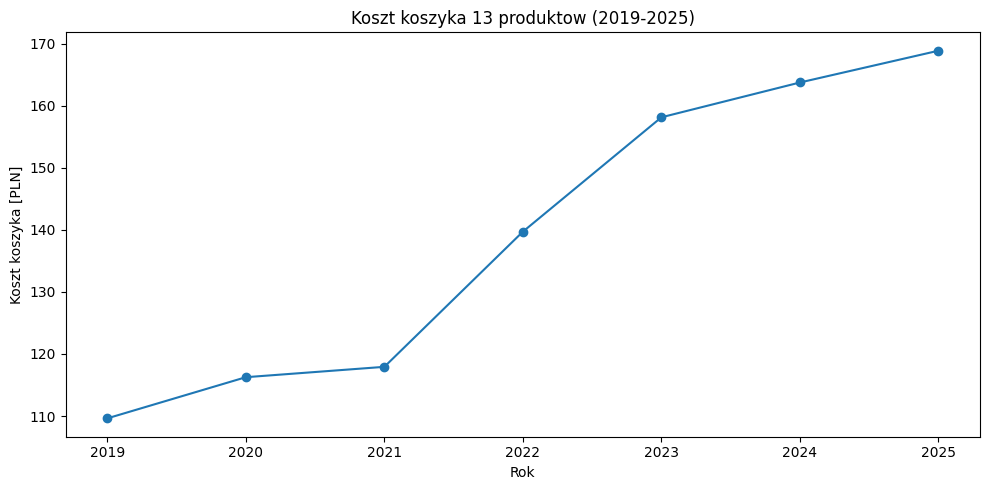

In [5]:
#wykres kosztu koszyka
plt.figure(figsize=(10, 5))
plt.plot(koszyk_roczny.index, koszyk_roczny.values, marker="o")
plt.title("Koszt koszyka 13 produktow (2019-2025)")
plt.xlabel("Rok")
plt.ylabel("Koszt koszyka [PLN]")
plt.xticks(koszyk_roczny.index)
plt.tight_layout()
plt.show()

W całym analizowanym okresie widoczny jest systematyczny wzrost kosztu koszyka, z 109,63 PLN w 2019 roku do 168,87 PLN w 2025 roku, co oznacza łączny wzrost o około 54%.

Największe podwyżki wystąpiły w latach 2022 i 2023, kiedy koszt koszyka wzrastał najszybciej. Od 2024 roku tempo wzrostu wyraźnie spadło, jednak ceny nadal rosły.

In [6]:
#polaczenie po wspolnym indeksie - roku
dane_polaczone = paliwa_roczne.join(koszyk_roczny, how="inner")

display(dane_polaczone.round(2))

,ONEkodiesel,Pb95,Pb98,Koszyk_13_prod
rok,,,,
2019,4.03,3.91,4.12,109.63
2020,3.35,3.43,3.60,116.26
2021,4.23,4.36,4.60,117.93
2022,6.69,5.94,6.39,139.71
2023,5.13,5.12,5.49,158.14
2024,4.98,4.90,5.42,163.75
2025,4.66,4.51,4.95,168.87


# Pytanie 1. Czy wzrostom cen paliw towarzyszyły wzrosty cen żywności?

Sprawdzamy zmiany roczne i oznaczamy lata, w których koszyk drożał pomimo spadku cen paliw.

,ONEkodiesel,Pb95,Pb98,Koszyk_13_prod
rok,,,,
2019,NaN,NaN,NaN,NaN
2020,-16.82,-12.29,-12.58,6.05
2021,26.25,27.13,27.85,1.44
2022,58.27,36.22,38.82,18.47
2023,-23.39,-13.80,-13.97,13.19
2024,-2.78,-4.29,-1.31,3.55
2025,-6.44,-8.06,-8.71,3.13


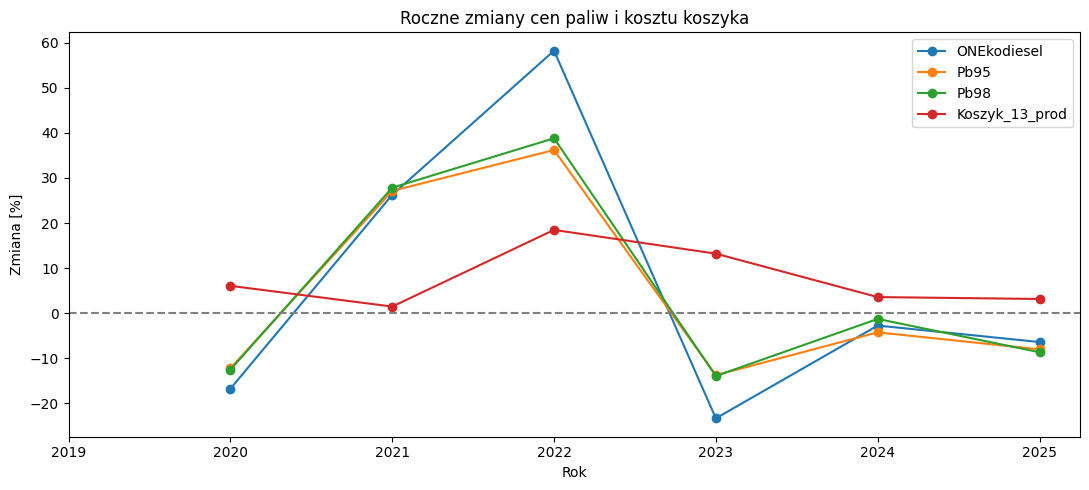

In [7]:
#procentowe zmiany rok do roku
zmiany_polaczone = dane_polaczone.pct_change(fill_method=None) * 100

display(zmiany_polaczone.round(2))

zmiany_polaczone.plot(marker="o", figsize=(11, 5))
plt.axhline(0, color="gray", linestyle="--")
plt.title("Roczne zmiany cen paliw i kosztu koszyka")
plt.xlabel("Rok")
plt.ylabel("Zmiana [%]")
plt.xticks(dane_polaczone.index)
plt.tight_layout()
plt.show()

In [9]:
#lata, w ktorych koszyk drozal, a ceny danego paliwa spadaly
for paliwo in ["ONEkodiesel", "Pb95", "Pb98"]:
    lata_rozbieznosci = zmiany_polaczone.index[
        (zmiany_polaczone["Koszyk_13_prod"] > 0) &
        (zmiany_polaczone[paliwo] < 0)
    ].tolist()
    print(paliwo, "- lata rozbieznych kierunkow:", lata_rozbieznosci)

ONEkodiesel - lata rozbieznych kierunkow: [2020, 2023, 2024, 2025]
Pb95 - lata rozbieznych kierunkow: [2020, 2023, 2024, 2025]
Pb98 - lata rozbieznych kierunkow: [2020, 2023, 2024, 2025]


Wykres przedstawia roczne zmiany procentowe cen trzech rodzajów paliw oraz kosztu koszyka 13 podstawowych produktów spożywczych w latach 2020-2025.

W 2021 i 2022 roku wzrostom cen wszystkich trzech paliw towarzyszył wzrost kosztu koszyka żywnościowego. Największe podwyżki wystąpiły w 2022 roku, kiedy cena ON Ekodiesel wzrosła o 58,27%, Pb95 o 36,22%, a Pb98 o 38,82%. W tym samym roku koszt koszyka wzrósł o 18,47%.

Jednak w latach 2020 oraz 2023-2025 zaobserwowano rozbieżne kierunki zmian. Pomimo spadków cen wszystkich paliw koszt koszyka żywnościowego nadal wzrastał. Szczególnie widoczne było to w 2023 roku, kiedy cena ON Ekodiesel spadła o 23,39%, natomiast koszt koszyka wzrósł o 13,19%.

Wyniki wskazują, że wzrostom cen paliw w niektórych latach towarzyszyły wzrosty cen żywności, jednak zależność ta nie występowała we wszystkich analizowanych latach. Sugeruje to, że na ceny produktów spożywczych wpływały również inne czynniki, a zmiany cen paliw nie przekładały się bezpośrednio na analogiczne zmiany kosztu koszyka.

Wniosek dla hipotezy H1: Na tym etapie hipoteza znajduje częściowe odzwierciedlenie w danych. W latach 2021-2022 ceny paliw i koszt koszyka rosły jednocześnie, ale w pozostałych czterech latach ich kierunki zmian były przeciwne. Sam wykres nie pozwala potwierdzić przyczynowego wpływu cen paliw na ceny żywności.

# Pytanie 2. Czy ceny paliw i żywności zmieniały się w podobnym tempie?

Porównujemy indeksy cen o wspólnej podstawie 2019 = 100, dzięki czemu porównujemy dynamikę, a nie różne jednostki cen.

,ONEkodiesel,Pb95,Pb98,Koszyk_13_prod
rok,,,,
2019,100.00,100.00,100.00,100.00
2020,83.18,87.71,87.42,106.05
2021,105.02,111.50,111.77,107.57
2022,166.22,151.89,155.15,127.44
2023,127.34,130.93,133.48,144.25
2024,123.80,125.32,131.73,149.37
2025,115.83,115.22,120.26,154.04


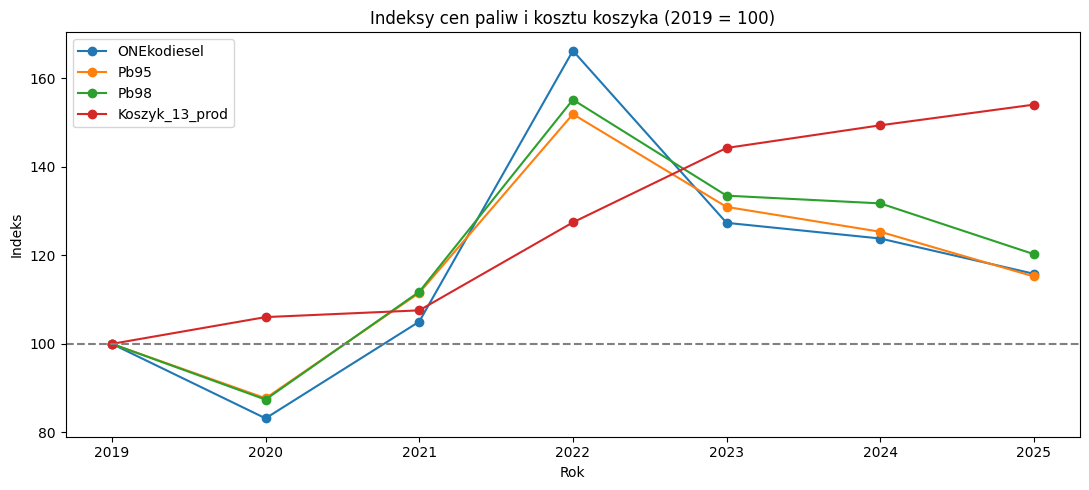

In [10]:
#indeksy: 2019 = 100
indeksy_polaczone = dane_polaczone / dane_polaczone.loc[2019] * 100

display(indeksy_polaczone.round(2))

indeksy_polaczone.plot(marker="o", figsize=(11, 5))
plt.axhline(100, color="gray", linestyle="--")
plt.title("Indeksy cen paliw i kosztu koszyka (2019 = 100)")
plt.xlabel("Rok")
plt.ylabel("Indeks")
plt.xticks(indeksy_polaczone.index)
plt.tight_layout()
plt.show()

W 2020 roku ceny wszystkich trzech paliw spadły poniżej poziomu bazowego, podczas gdy koszt koszyka żywnościowego wzrósł o 6,05%.

Największy wzrost cen paliw wystąpił w 2022 roku, szczególnie dla ON Ekodiesel, którego indeks osiągnął 166,22. W tym samym roku indeks kosztu koszyka wyniósł 127,44, co wskazuje, że ceny paliw rosły znacznie szybciej niż ceny analizowanej żywności. Od 2023 roku widoczna jest wyraźna rozbieżność: indeksy cen paliw stopniowo malały, natomiast indeks kosztu koszyka nadal wzrastał. W 2025 roku koszt koszyka był o 54,04% wyższy niż w 2019 roku, podczas gdy ceny paliw wzrosły o 15,22-20,26%.

Wyniki wskazują, że ceny paliw i żywności nie zmieniały się w jednakowym tempie. Ceny paliw charakteryzowały się gwałtowniejszymi wahaniami, natomiast koszt koszyka żywnościowego wykazywał systematyczny wzrost w całym analizowanym okresie.

Ceny paliw i żywności wykazywały różną dynamikę. Szczególnie istotny jest okres 2023-2025, kiedy mimo spadków cen paliw koszt koszyka nadal wzrastał.

# Pytanie 3. Czy zmiany cen paliw były związane ze zmianami kosztu koszyka?

Dla H1 obliczamy korelację Pearsona rocznych zmian procentowych, a także sprawdzamy wariant z opóźnieniem o rok. Przy 7 latach mamy tylko 6 zmian rocznych, a w analizie opóźnienia tylko 5 par.

,ONEkodiesel,Pb95,Pb98,Koszyk_13_prod
ONEkodiesel,1.00,0.97,0.98,0.39
Pb95,0.97,1.00,1.00,0.30
Pb98,0.98,1.00,1.00,0.31
Koszyk_13_prod,0.39,0.30,0.31,1.00


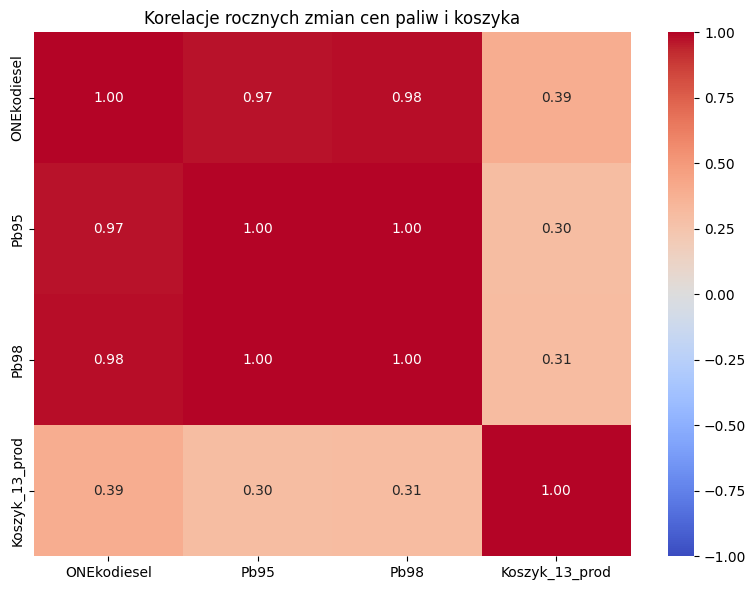

In [11]:
#korelacje rocznych zmian procentowych
korelacje_wspolne = zmiany_polaczone.corr()

display(korelacje_wspolne.round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(korelacje_wspolne, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelacje rocznych zmian cen paliw i koszyka")
plt.tight_layout()
plt.show()

In [12]:
#korelacja tylko z kosztem koszyka
korelacje_z_koszykiem = korelacje_wspolne["Koszyk_13_prod"].drop("Koszyk_13_prod")
display(korelacje_z_koszykiem.round(3))

,Koszyk_13_prod
ONEkodiesel,0.391
Pb95,0.302
Pb98,0.308


In [13]:
#zmiana cen paliwa w danym roku vs zmiana koszyka w kolejnym roku
for paliwo in ["ONEkodiesel", "Pb95", "Pb98"]:
    r = zmiany_polaczone[paliwo].corr(zmiany_polaczone["Koszyk_13_prod"].shift(-1))
    print(paliwo, "- korelacja z opoznieniem 1 roku:", round(r, 3))

ONEkodiesel - korelacja z opoznieniem 1 roku: 0.799
Pb95 - korelacja z opoznieniem 1 roku: 0.91
Pb98 - korelacja z opoznieniem 1 roku: 0.895


W przypadku analizy bez opóźnienia zaobserwowano słabe dodatnie korelacje między zmianami cen paliw a kosztem koszyka. Najwyższą wartość odnotowano dla ON Ekodiesel (r = 0,39), natomiast dla Pb95 i Pb98 współczynniki wyniosły odpowiednio 0,30 i 0,31. Znacznie silniejsze zależności wystąpiły po uwzględnieniu opóźnienia o jeden rok. Korelacja dla Pb95 wzrosła do 0,91, dla Pb98 do 0,90, a dla ON Ekodiesel do 0,80.

Wyniki mogą sugerować, że zmiany cen paliw są powiązane ze zmianami kosztów żywności z pewnym opóźnieniem, co może wynikać ze stopniowego przenoszenia kosztów transportu i dystrybucji na ceny produktów.

Należy jednak zaznaczyć, że analiza obejmuje jedynie 6 rocznych zmian, a w przypadku korelacji z opóźnieniem tylko 5 par obserwacji. Dlatego otrzymane wyniki mają charakter wstępny i nie stanowią dowodu zależności przyczynowo-skutkowej.

Wniosek dla hipotezy H1: Wyniki wskazują na dodatnią zależność między zmianami cen paliw a kosztem koszyka, szczególnie po uwzględnieniu rocznego opóźnienia. Stanowi to wstępną przesłankę zgodną z hipotezą H1, ale nie wystarcza do jej jednoznacznego potwierdzenia.

# Pytanie 4. Czy wzrost kosztu koszyka ograniczył możliwości zakupowe konsumentów?

Dla H2 sprawdzamy, ile równoważnych koszyków można kupić za stałe 200 zł. To model porównawczy: nie pokazuje rzeczywistych zakupów ani zmian dochodów.

In [14]:
#staly budzet na zakupy
budzet = 200

#ile rownowaznych koszykow mozna kupic za 200 zl
liczba_koszykow = budzet / koszyk_roczny

#indeks sily nabywczej stalej kwoty wobec koszyka (2019 = 100)
sila_nabywcza_koszyk = koszyk_roczny.loc[2019] / koszyk_roczny * 100

wyniki_budzet = pd.DataFrame({
    "Koszt_koszyka_PLN": koszyk_roczny,
    "Liczba_koszykow_za_200_PLN": liczba_koszykow,
    "Sila_nabywcza_2019_100": sila_nabywcza_koszyk
})
display(wyniki_budzet.round(2))

,Koszt_koszyka_PLN,Liczba_koszykow_za_200_PLN,Sila_nabywcza_2019_100
2019,109.63,1.82,100.00
2020,116.26,1.72,94.30
2021,117.93,1.70,92.96
2022,139.71,1.43,78.47
2023,158.14,1.26,69.32
2024,163.75,1.22,66.95
2025,168.87,1.18,64.92


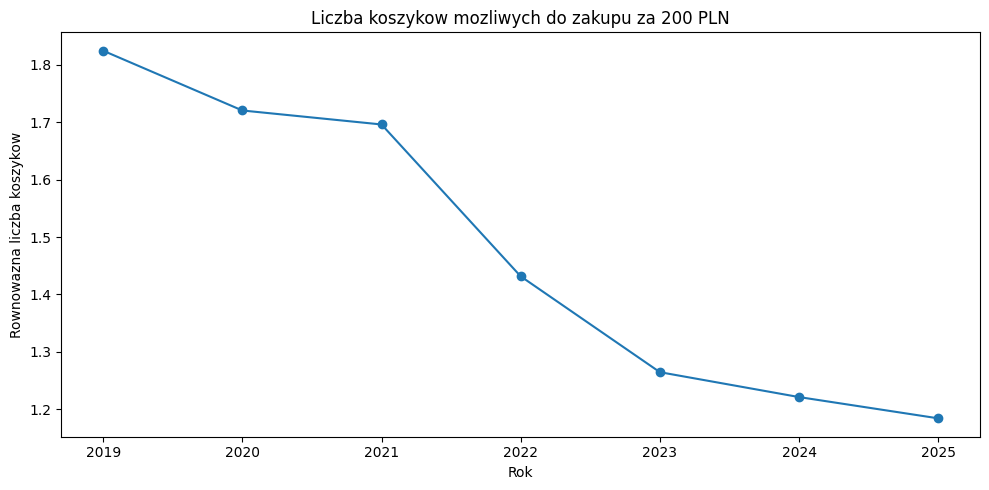

In [15]:
#wykres mozliwosci zakupowych
plt.figure(figsize=(10, 5))
plt.plot(liczba_koszykow.index, liczba_koszykow.values, marker="o")
plt.title("Liczba koszykow mozliwych do zakupu za 200 PLN")
plt.xlabel("Rok")
plt.ylabel("Rownowazna liczba koszykow")
plt.xticks(liczba_koszykow.index)
plt.tight_layout()
plt.show()

Analiza przedstawia zmianę możliwości zakupowych konsumentów w latach 2019-2025 przy założeniu stałego budżetu wynoszącego 200 PLN, w 2019 roku za tę kwotę można było zakupić równowartość 1,82 koszyka 13 podstawowych produktów spożywczych, natomiast w 2025 roku już tylko 1,18 koszyka.

Wskaźnik siły nabywczej, przyjmujący rok 2019 jako bazowy (2019 = 100), systematycznie malał, osiągając w 2025 roku wartość 64,92. Oznacza to spadek możliwości zakupowych o około 35,08% względem 2019 roku.


Hipoteza H2 została potwierdzona w przyjętym modelu stałego budżetu. Wzrost kosztu koszyka 13 podstawowych produktów spożywczych w latach 2019-2025 spowodował zmniejszenie liczby koszyków możliwych do zakupienia za niezmienioną kwotę 200 PLN o około 35,08%.

Wynik ten wskazuje na spadek siły nabywczej stałej kwoty pieniędzy względem analizowanego koszyka, jednak nie oznacza automatycznie pogorszenia rzeczywistej sytuacji finansowej konsumentów, ponieważ analiza nie uwzględnia zmian ich dochodów.

# Pytanie 5. Czy większa zmienność paliw wiązała się z większymi podwyżkami koszyka?
Dla H3 mierzymy odchylenie standardowe miesięcznych zmian procentowych cen paliw w każdym roku. Jest to miara historycznej zmienności, nie bezpośredni pomiar niepewności konsumentów. Następnie zestawiamy ją z roczną zmianą kosztu koszyka.

productName,ONEkodiesel,Pb95,Pb98,Zmiana_koszyka_%
rok,,,,
2019,2.68,4.39,3.95,NaN
2020,5.73,7.89,7.73,6.05
2021,4.30,4.56,3.94,1.44
2022,11.56,10.01,10.18,18.47
2023,5.49,4.92,4.81,13.19
2024,3.20,3.67,4.87,3.55
2025,3.72,2.18,1.98,3.13


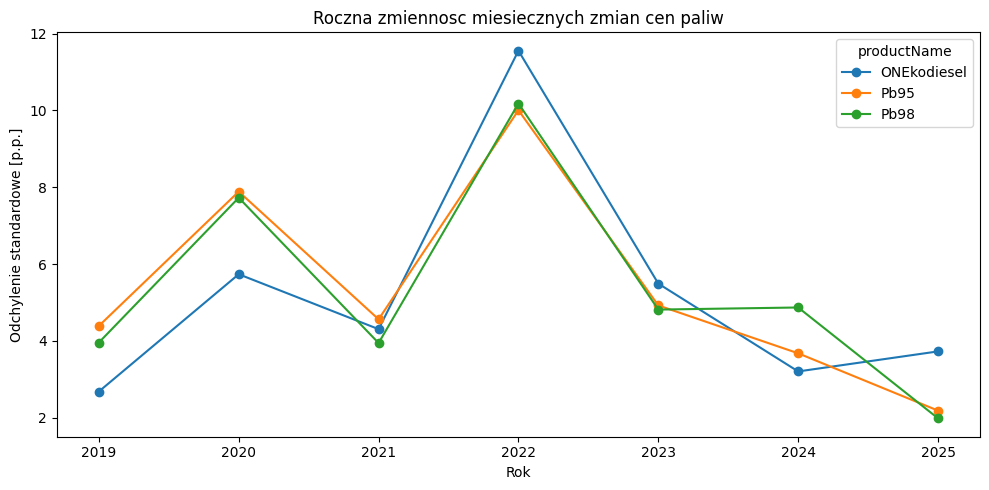

In [18]:
#dane miesieczne - mediany z notebooka paliwowego
plik_miesieczny = "paliwa_mediany_miesieczne.csv"
if not Path(plik_miesieczny).exists():
    from google.colab import files
    files.upload()

miesieczne = pd.read_csv(plik_miesieczny, sep=";", decimal=",")
miesieczne["data"] = pd.to_datetime(dict(
    year=miesieczne["rok"], month=miesieczne["miesiac"], day=1
))

#zmiany miesieczne i ich odchylenie standardowe w danym roku
miesieczne_tabela = miesieczne.pivot(
    index="data", columns="productName", values="cena_za_litr"
).sort_index()

miesieczne_zmiany = miesieczne_tabela.pct_change(fill_method=None) * 100
zmiennosc_roczna = miesieczne_zmiany.groupby(miesieczne_zmiany.index.year).std()
zmiennosc_roczna.index.name = "rok"
zmiennosc_roczna["Zmiana_koszyka_%"] = zmiany_polaczone["Koszyk_13_prod"]

display(zmiennosc_roczna.round(2))

zmiennosc_roczna[["ONEkodiesel", "Pb95", "Pb98"]].plot(marker="o", figsize=(10, 5))
plt.title("Roczna zmiennosc miesiecznych zmian cen paliw")
plt.ylabel("Odchylenie standardowe [p.p.]")
plt.xlabel("Rok")
plt.tight_layout()
plt.show()

Wykres przedstawia roczną zmienność miesięcznych zmian procentowych cen paliw w latach 2019-2025, mierzoną za pomocą odchylenia standardowego. Największą zmienność cen wszystkich trzech paliw odnotowano w 2022 roku, szczególnie dla ON Ekodiesel (11,56 p.p.), Pb98 (10,18 p.p.) oraz Pb95 (10,01 p.p.). W tym samym roku wystąpił również największy roczny wzrost kosztu koszyka żywnościowego (18,47%).

Podwyższoną zmienność cen paliw zaobserwowano także w 2020 roku, jednak wzrost kosztu koszyka był wtedy znacznie mniejszy (6,05%). Z kolei w 2023 roku, pomimo spadku zmienności cen paliw, koszt koszyka wzrósł o 13,19%.

Wyniki sugerują, że większej zmienności cen paliw w niektórych latach towarzyszyły większe podwyżki cen żywności, jednak zależność ta nie występowała jednakowo w całym analizowanym okresie.

Korelacje rocznej zmiennosci paliw ze wzrostem kosztu koszyka:


,0
productName,
ONEkodiesel,0.878
Pb95,0.723
Pb98,0.729


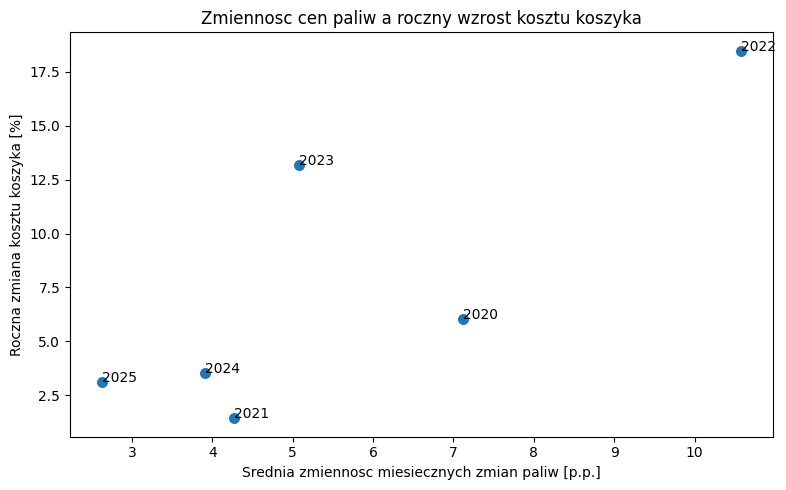

In [19]:
#H3 - korelacja zmiennosci kazdego paliwa ze zmiana kosztu koszyka
korelacje_zmiennosci = zmiennosc_roczna[["ONEkodiesel", "Pb95", "Pb98"]].corrwith(
    zmiennosc_roczna["Zmiana_koszyka_%"]
)

print("Korelacje rocznej zmiennosci paliw ze wzrostem kosztu koszyka:")
display(korelacje_zmiennosci.round(3))

#dodatkowo srednia zmiennosc trzech paliw w danym roku
zmiennosc_roczna["Srednia_zmiennosc_paliw"] = zmiennosc_roczna[
    ["ONEkodiesel", "Pb95", "Pb98"]
].mean(axis=1)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=zmiennosc_roczna.dropna(),
    x="Srednia_zmiennosc_paliw", y="Zmiana_koszyka_%", s=75
)
for rok, wiersz in zmiennosc_roczna.dropna().iterrows():
    plt.annotate(str(rok), (wiersz["Srednia_zmiennosc_paliw"], wiersz["Zmiana_koszyka_%"]))
plt.title("Zmiennosc cen paliw a roczny wzrost kosztu koszyka")
plt.xlabel("Srednia zmiennosc miesiecznych zmian paliw [p.p.]")
plt.ylabel("Roczna zmiana kosztu koszyka [%]")
plt.tight_layout()
plt.show()

Najwyższą zmienność cen paliw oraz największy wzrost kosztu koszyka odnotowano w 2022 roku (18,47%). W 2023 roku koszt koszyka nadal znacząco wzrastał (13,19%), mimo niższej zmienności cen paliw. Analiza korelacji wykazała silną dodatnią zależność dla ON Ekodiesel (r = 0,878) oraz dodatnie zależności dla Pb95 (r = 0,723) i Pb98 (r = 0,729).

Wyniki sugerują, że w latach większej zmienności cen paliw często występowały również większe podwyżki kosztu koszyka żywnościowego. Zależność ta nie była jednak jednakowa we wszystkich latach.

Ze względu na niewielką liczbę obserwacji (6 lat) oraz możliwy wpływ innych czynników gospodarczych wyniki należy interpretować ostrożnie i nie stanowią one dowodu bezpośredniego wpływu zmienności cen paliw na ceny żywności.

**Wniosek dla H3:** Uzyskane wyniki są zgodne z kierunkiem hipotezy H3 i wskazują na dodatnią zależność między zmiennością cen paliw a wzrostem kosztu koszyka. Nie pozwalają jednak jednoznacznie potwierdzić zależności przyczynowo-skutkowej.